In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('/content/telco_customer_churn.csv')

# Display the first 5 records
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check column names and data types
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling

In [3]:
# Convert TotalCharges into numeric format
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'], errors='coerce'
)

# Check missing values after conversion
print("Missing TotalCharges:",
      df['TotalCharges'].isnull().sum())

# Display records with missing TotalCharges
df[df['TotalCharges'].isnull()]

Missing TotalCharges: 11


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [4]:
# Handle missing charges for zero-tenure customers
df.loc[
    (df['tenure'] == 0) & (df['TotalCharges'].isnull()),
    'TotalCharges'
] = 0

# Remove duplicate records
df = df.drop_duplicates()

# Verify cleaned dataset
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Records:", df.duplicated().sum())
print("Final Dataset Shape:", df.shape)

Missing Values: 0
Duplicate Records: 0
Final Dataset Shape: (7043, 21)


In [5]:
# Calculate customer churn metrics
total_customers = len(df)

churned_customers = (df['Churn'] == 'Yes').sum()

retained_customers = (df['Churn'] == 'No').sum()

churn_rate = (churned_customers / total_customers) * 100

retention_rate = (retained_customers / total_customers) * 100

# Display KPI results
print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Retained Customers:", retained_customers)
print(f"Churn Rate: {churn_rate:.2f}%")
print(f"Retention Rate: {retention_rate:.2f}%")

Total Customers: 7043
Churned Customers: 1869
Retained Customers: 5174
Churn Rate: 26.54%
Retention Rate: 73.46%


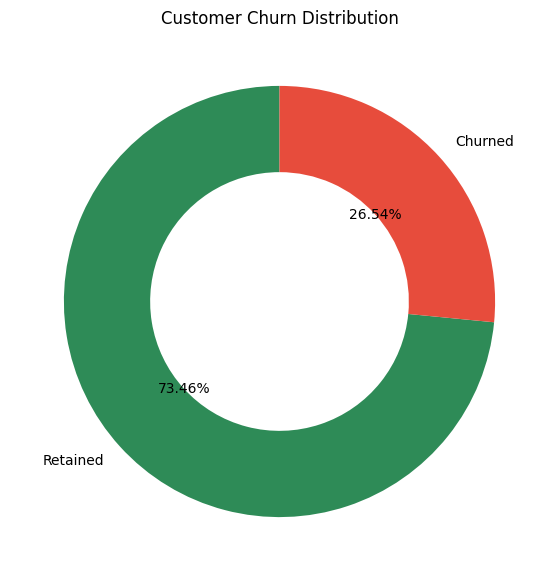

In [6]:
# Customer churn distribution
plt.figure(figsize=(7, 7))

plt.pie(
    [retained_customers, churned_customers],
    labels=['Retained', 'Churned'],
    autopct='%1.2f%%',
    colors=['#2E8B57', '#E74C3C'],
    startangle=90,
    wedgeprops={'width': 0.4}
)

plt.title('Customer Churn Distribution')
plt.show()

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


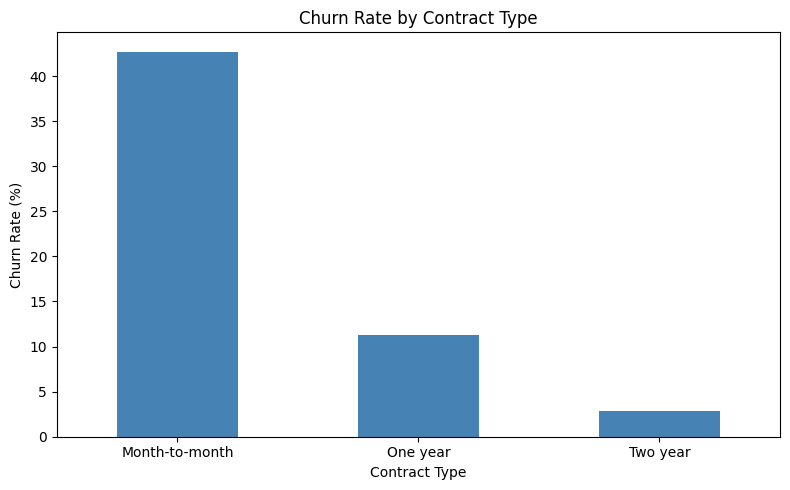

In [7]:
# Calculate churn rate by contract type
contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

print(contract_churn.round(2))

# Visualize churn rate
plt.figure(figsize=(8, 5))

contract_churn['Yes'].plot(
    kind='bar',
    color='#4682B4'
)

plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Churn            No    Yes
Tenure_Group              
0-12 Months   52.56  47.44
13-24 Months  71.29  28.71
25-36 Months  78.37  21.63
37-48 Months  80.97  19.03
49-60 Months  85.58  14.42
61-72 Months  93.39   6.61


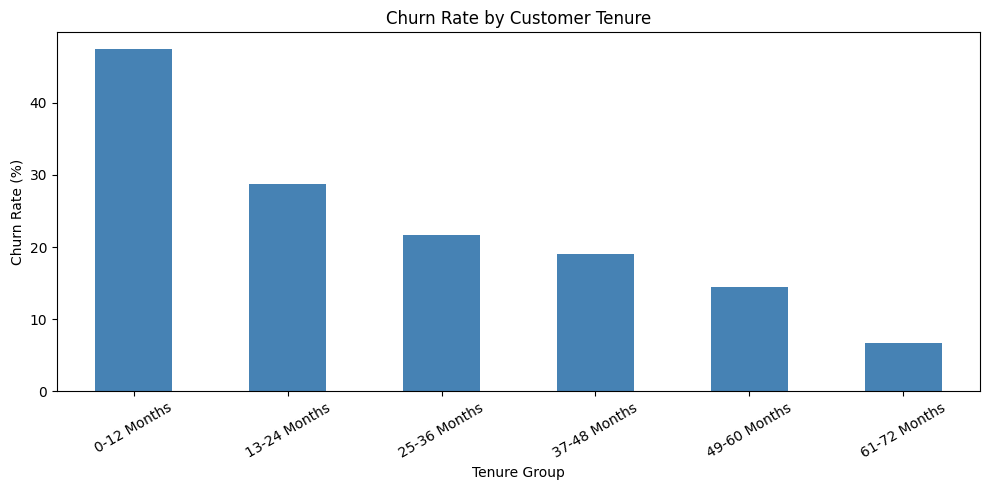

In [8]:
# Create customer tenure cohorts
df['Tenure_Group'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 24, 36, 48, 60, 72],
    labels=[
        '0-12 Months',
        '13-24 Months',
        '25-36 Months',
        '37-48 Months',
        '49-60 Months',
        '61-72 Months'
    ]
)

# Calculate churn rate by tenure group
tenure_churn = pd.crosstab(
    df['Tenure_Group'],
    df['Churn'],
    normalize='index'
) * 100

print(tenure_churn.round(2))

# Visualize tenure-wise churn
plt.figure(figsize=(10, 5))
tenure_churn['Yes'].plot(
    kind='bar',
    color='#4682B4'
)

plt.title('Churn Rate by Customer Tenure')
plt.xlabel('Tenure Group')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


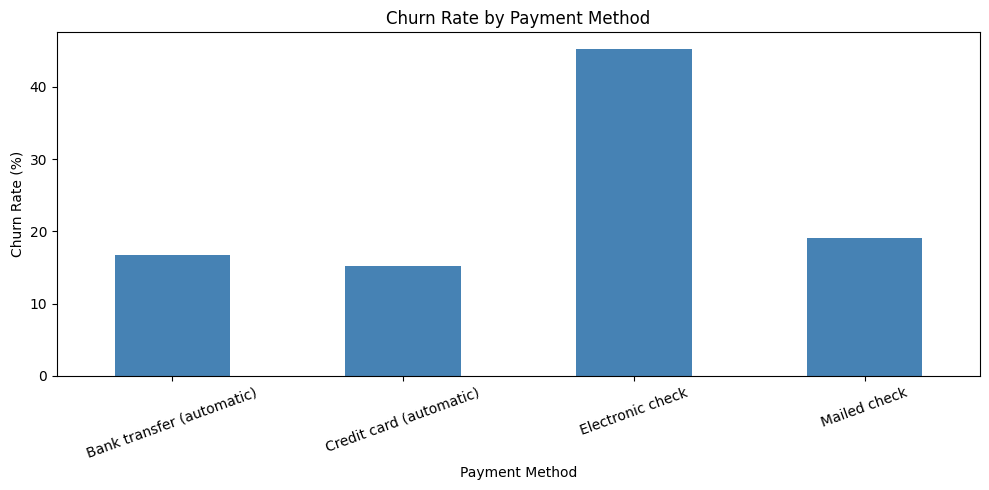

In [9]:
# Calculate churn rate by payment method
payment_churn = pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
) * 100

print(payment_churn.round(2))

# Visualize payment-wise churn
plt.figure(figsize=(10, 5))

payment_churn['Yes'].plot(
    kind='bar',
    color='#4682B4'
)

plt.title('Churn Rate by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Churn            No    Yes
Charge_Group              
0-30          90.20   9.80
30-60         74.07  25.93
60-90         66.09  33.91
90+           67.22  32.78


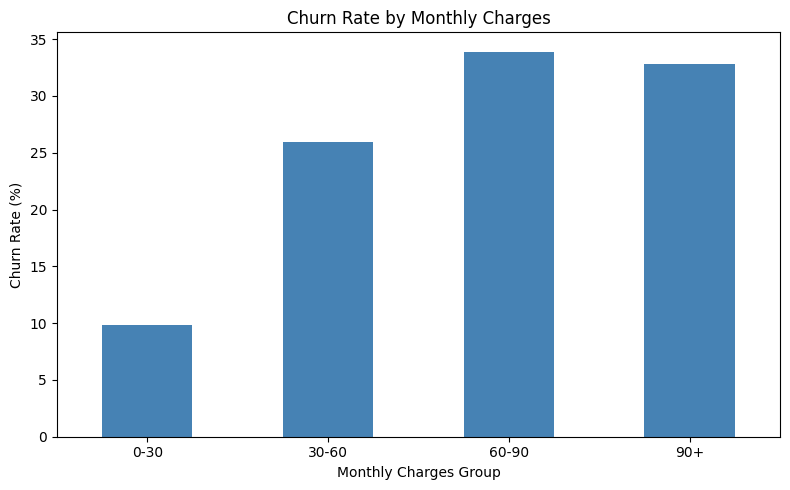

In [10]:
# Create monthly charge groups
df['Charge_Group'] = pd.cut(
    df['MonthlyCharges'],
    bins=[0, 30, 60, 90, float('inf')],
    labels=['0-30', '30-60', '60-90', '90+'],
    include_lowest=True
)

# Calculate churn rate
charge_churn = pd.crosstab(
    df['Charge_Group'],
    df['Churn'],
    normalize='index'
) * 100

print(charge_churn.round(2))

# Visualize monthly charges and churn
plt.figure(figsize=(8, 5))

charge_churn['Yes'].plot(
    kind='bar',
    color='#4682B4'
)

plt.title('Churn Rate by Monthly Charges')
plt.xlabel('Monthly Charges Group')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

  InternetService          TechSupport  Churn_Rate
2     Fiber optic                   No       49.37
0             DSL                   No       27.76
3     Fiber optic                  Yes       22.63
1             DSL                  Yes        9.68
4              No  No internet service        7.40


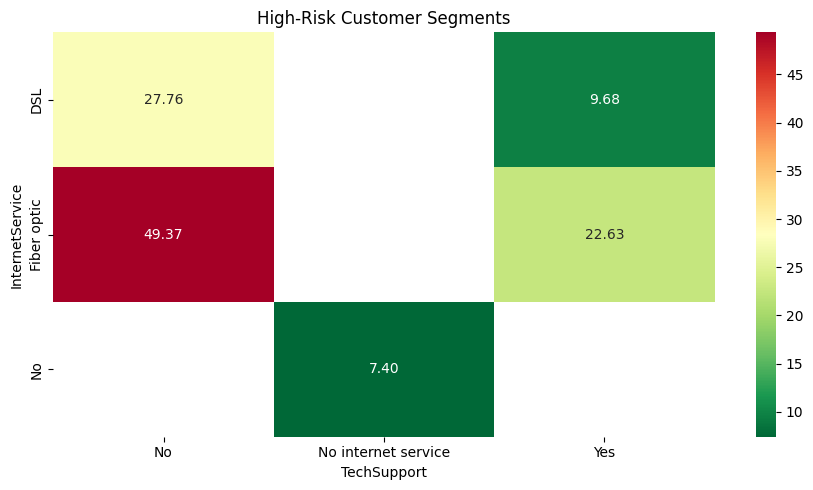

In [11]:
# Calculate churn by internet service and technical support
high_risk = df.groupby(
    ['InternetService', 'TechSupport']
)['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
).reset_index(name='Churn_Rate')

# Sort by highest churn rate
high_risk = high_risk.sort_values(
    'Churn_Rate', ascending=False
)

print(high_risk.round(2))

# Create heatmap
risk_matrix = high_risk.pivot(
    index='InternetService',
    columns='TechSupport',
    values='Churn_Rate'
)

plt.figure(figsize=(9, 5))

sns.heatmap(
    risk_matrix,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn_r'
)

plt.title('High-Risk Customer Segments')
plt.tight_layout()
plt.show()

Contract      Month-to-month  One year  Two year
Tenure_Group                                    
0-12 Months            48.65     89.52    100.00
13-24 Months           62.28     91.88    100.00
25-36 Months           67.49     92.00     97.92
37-48 Months           66.46     86.94     97.75
49-60 Months           72.22     86.29     96.03
61-72 Months           77.78     87.86     96.86


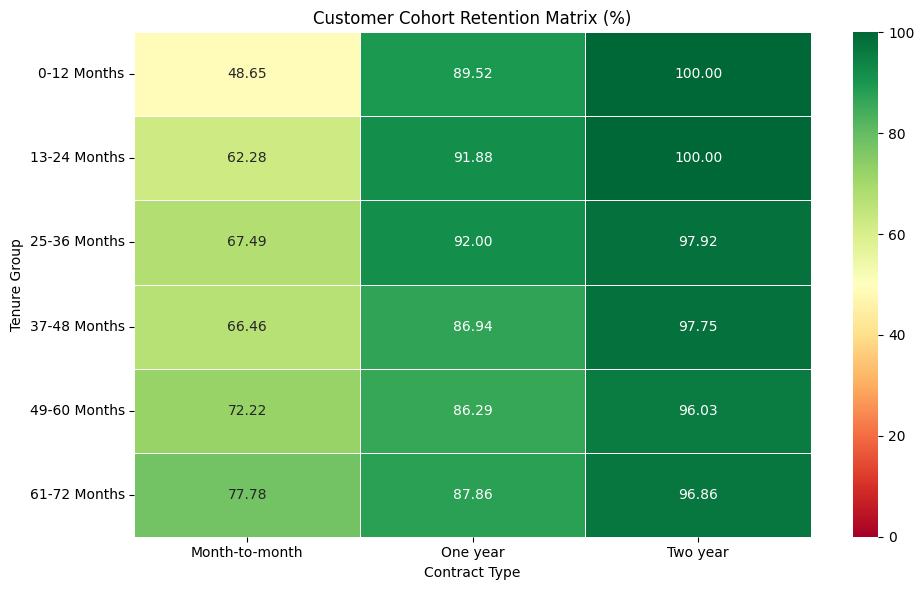

In [12]:
# Create retention indicator
df['Retained'] = (df['Churn'] == 'No').astype(int)

# Create cohort retention matrix
retention_matrix = df.pivot_table(
    index='Tenure_Group',
    columns='Contract',
    values='Retained',
    aggfunc='mean',
    observed=True
) * 100

print(retention_matrix.round(2))

# Visualize retention matrix
plt.figure(figsize=(10, 6))

sns.heatmap(
    retention_matrix,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    vmin=0,
    vmax=100,
    linewidths=0.5
)

plt.title('Customer Cohort Retention Matrix (%)')
plt.xlabel('Contract Type')
plt.ylabel('Tenure Group')
plt.tight_layout()
plt.show()

In [13]:
# Identify high-risk customer segments
risk_segments = df.groupby(
    ['Contract', 'Tenure_Group'],
    observed=True
).agg(
    Total_Customers=('customerID', 'count'),
    Churned_Customers=('Churn', lambda x: (x == 'Yes').sum())
).reset_index()

# Calculate churn percentage
risk_segments['Churn_Rate'] = (
    risk_segments['Churned_Customers'] /
    risk_segments['Total_Customers']
) * 100

# Display top 5 high-risk segments
risk_segments = risk_segments.sort_values(
    'Churn_Rate', ascending=False
)

risk_segments.head(5).round(2)

,Contract,Tenure_Group,Total_Customers,Churned_Customers,Churn_Rate
0,Month-to-month,0-12 Months,1994,1024,51.35
1,Month-to-month,13-24 Months,737,278,37.72
3,Month-to-month,37-48 Months,316,106,33.54
2,Month-to-month,25-36 Months,486,158,32.51
4,Month-to-month,49-60 Months,234,65,27.78


## Business Insights and Strategic Retention Recommendations

### Key Findings

- The overall customer churn rate is 26.54%, while the retention rate is 73.46%.
- Month-to-month customers have the highest churn rate of 42.71%.
- Two-year contract customers have the lowest churn rate of 2.83%.
- Month-to-month customers with 0–12 months of tenure have a churn rate of 51.35%.
- Longer-term contracts are associated with lower observed churn rates.

### Strategic Recommendations

1. Encourage customers to choose long-term contracts through attractive discounts.
2. Improve customer onboarding and engagement during the first year.
3. Provide proactive technical support to high-risk customers.
4. Introduce loyalty rewards and personalized retention offers.
5. Regularly monitor customer churn and retention metrics.

### Conclusion

Customer cohort and churn analysis helps businesses identify high-risk customer segments and develop targeted retention strategies to improve customer satisfaction and business performance.

### Analysis Limitation

The dataset represents a customer snapshot. The findings indicate observed associations rather than causal relationships or historical retention trends.

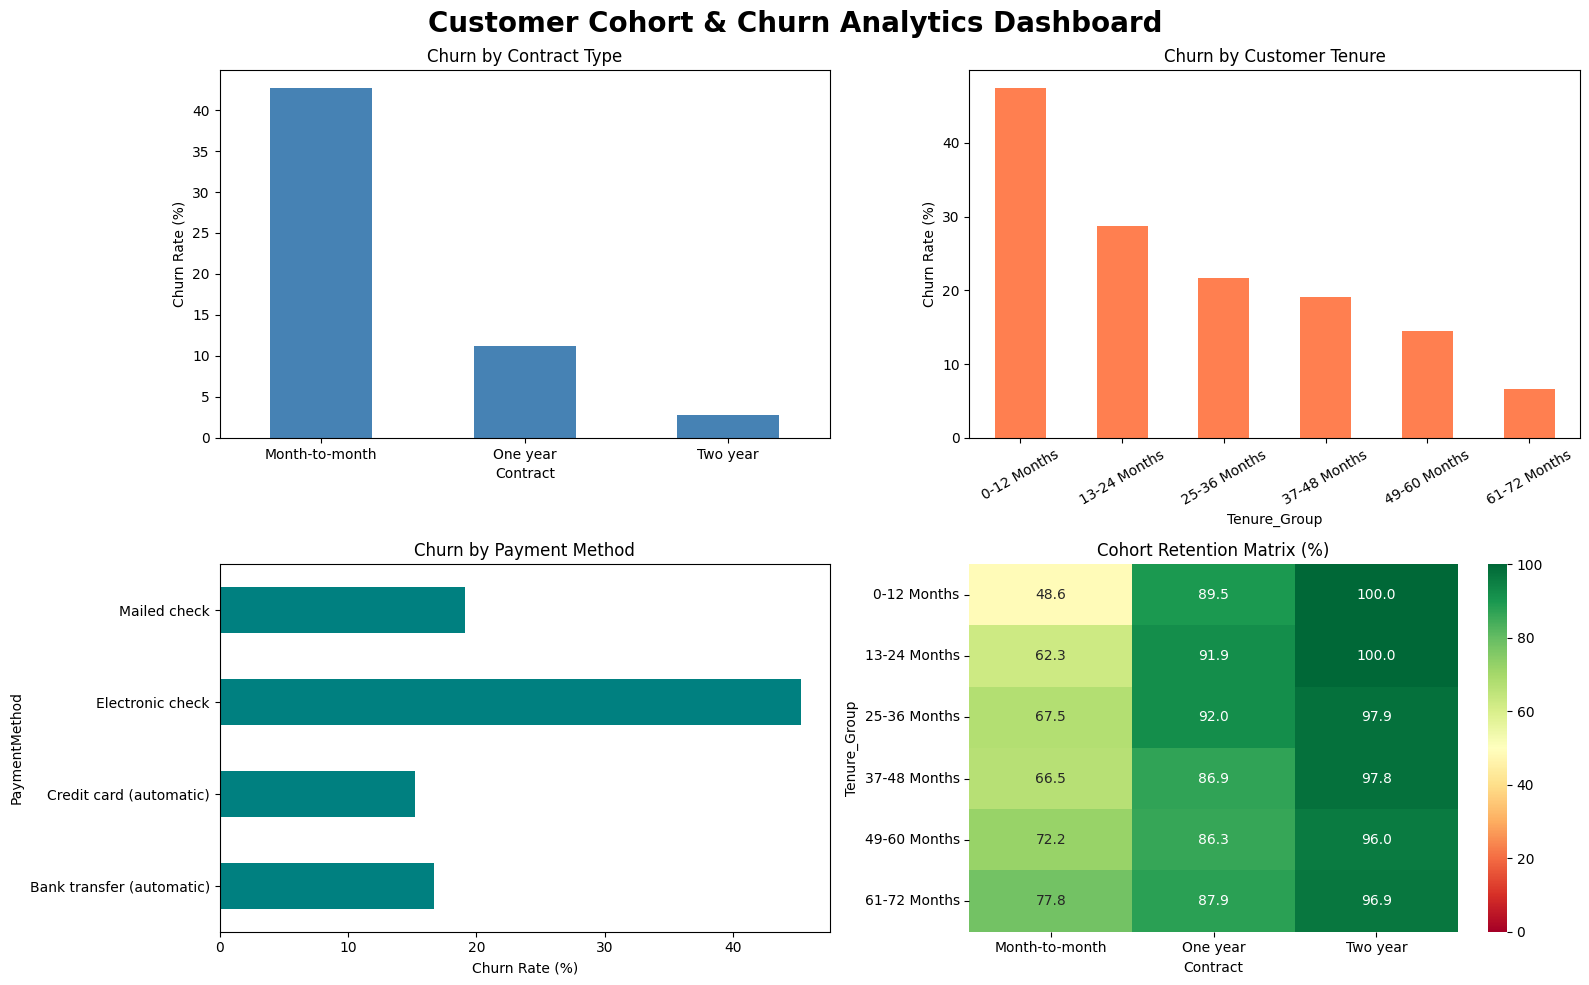

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Contract-wise churn
contract_churn['Yes'].plot(
    kind='bar', ax=axes[0, 0], color='steelblue'
)
axes[0, 0].set_title('Churn by Contract Type')
axes[0, 0].set_ylabel('Churn Rate (%)')
axes[0, 0].tick_params(axis='x', rotation=0)

# Tenure-wise churn
tenure_churn['Yes'].plot(
    kind='bar', ax=axes[0, 1], color='coral'
)
axes[0, 1].set_title('Churn by Customer Tenure')
axes[0, 1].set_ylabel('Churn Rate (%)')
axes[0, 1].tick_params(axis='x', rotation=30)

# Payment method churn
payment_churn['Yes'].plot(
    kind='barh', ax=axes[1, 0], color='teal'
)
axes[1, 0].set_title('Churn by Payment Method')
axes[1, 0].set_xlabel('Churn Rate (%)')

# Cohort retention heatmap
sns.heatmap(
    retention_matrix,
    annot=True,
    fmt='.1f',
    cmap='RdYlGn',
    vmin=0,
    vmax=100,
    ax=axes[1, 1]
)
axes[1, 1].set_title('Cohort Retention Matrix (%)')

fig.suptitle(
    'Customer Cohort & Churn Analytics Dashboard',
    fontsize=20,
    fontweight='bold'
)

plt.tight_layout()

plt.savefig(
    'Customer_Churn_Dashboard.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()